# Function 6 - Week 8: Observation review

Review the round 7 return received on **12 November 2026 at 03:39 GMT**. The official snapshot contains **20 starting observations and seven returns (27 rows)** across 5 input coordinates.

The latest signed output is **-0.213959540335**, ranked **1/27**. The returned score improved the previous best of -0.328192387858. Six queries remain per function, including Week 8.

Continue in [model predictions](model_predictions.ipynb) and the [week-level report](report.md).


In [1]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "exploration_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's own week folder.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))
from exploration_review_helpers import load_exploration_review
from observation_review_helpers import (
    prepare_weekly_observation_review, plot_input_profiles,
    plot_output_review, plot_round_progress,
)
from query_budget import remaining_queries

print("Python:", sys.executable)


Python: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


In [2]:
FUNCTION_NUMBER = 6
CURRENT_WEEK = 8
INPUT_COLUMNS = ['x1', 'x2', 'x3', 'x4', 'x5']
OUTPUT_COLUMN = "y"
EXPECTED_ROUND_COUNTS = {0: 20, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1}
ANALYSIS_DIR = Path.cwd().resolve()
WEEK_DIR = ANALYSIS_DIR.parent if ANALYSIS_DIR.name == "official" else ANALYSIS_DIR
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"


In [3]:
review = load_exploration_review(
    DATA_PATH, input_columns=INPUT_COLUMNS, output_column=OUTPUT_COLUMN,
    expected_round_counts=EXPECTED_ROUND_COUNTS,
)
prepared = prepare_weekly_observation_review(review)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
display(review["latest_submissions"].drop(columns="comparison"))
print(review["report"])


,observation_id,source_round,x1,x2,x3,x4,x5,y,output_rank
26,round-07,7,0.414821,0.260324,0.607614,0.728412,0.0,-0.21396,1


Latest recorded submission: round 7 (1 new output).
Compared with 26 earlier observations (27 outputs in total).
Earlier output range: [-2.57116963161, -0.328192387858].

round-07: y = -0.213959540335 (negative); rank 1/27 (1 = highest output).
Inputs: x1 = 0.414821, x2 = 0.260324, x3 = 0.607614, x4 = 0.728412, x5 = 0
New highest observed output. Smallest non-zero magnitude so far (1.53 times smaller than the earlier smallest).


### Measured outputs

Both panels use signed outputs in their original units. The close-up shows only the highest five; all observations remain in the full-range panel and calculations.

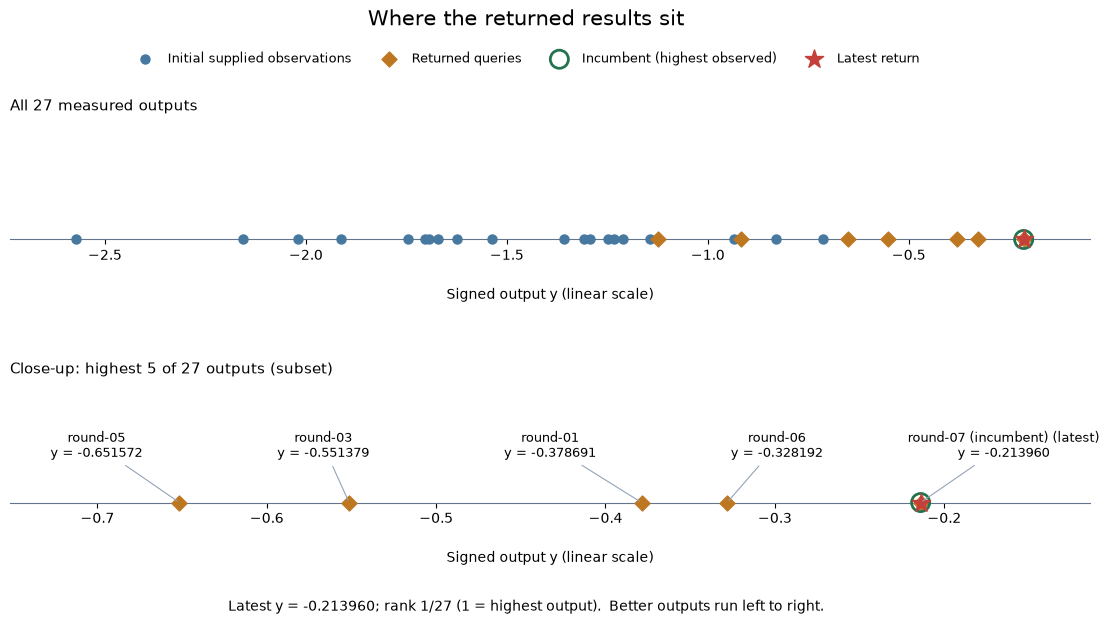

In [4]:
plot_output_review(review, save_to=FIGURES_DIR / "observed-output-review.png")

### Progress across completed rounds

The initial rows form one starting batch. Compare each return with the best known before that round.

In [5]:
display(prepared["progress"].set_index("stage")[["returned_y", "best_y", "change_vs_prior_best"]]
    .rename(columns={"returned_y": "Returned output", "best_y": "Best observed after stage",
                     "change_vs_prior_best": "Return minus previous best"})
    .style.format(precision=6, na_rep="Not applicable"))


,Returned output,Best observed after stage,Return minus previous best
stage,,,
Initial batch,Not applicable,-0.714265,Not applicable
Round 1,-0.378691,-0.378691,0.335574
Round 2,-1.124281,-0.378691,-0.745590
Round 3,-0.551379,-0.378691,-0.172688
Round 4,-0.917070,-0.378691,-0.538379
Round 5,-0.651572,-0.378691,-0.272881
Round 6,-0.328192,-0.328192,0.050499
Round 7,-0.213960,-0.213960,0.114233


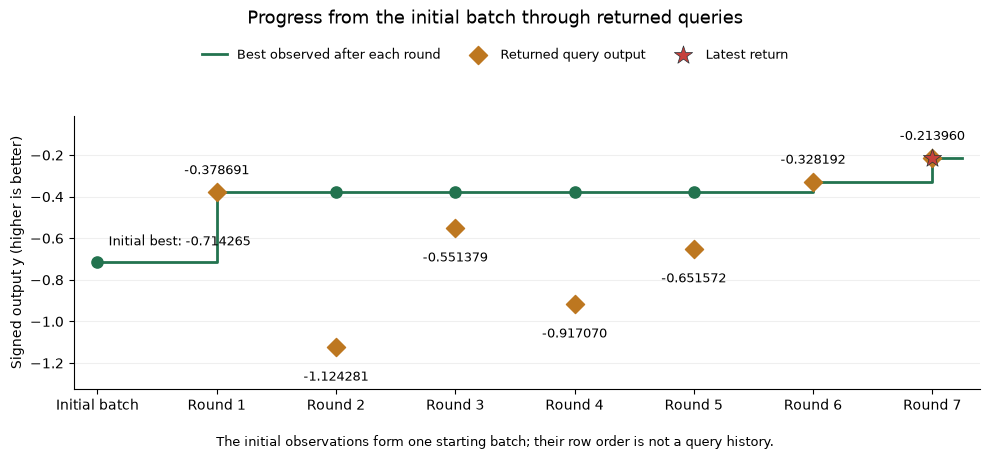

In [6]:
plot_round_progress(prepared["progress"], save_to=FIGURES_DIR / "observed-progress.png")

### Strongest measured input combinations

Keep all 5 coordinates visible. Colour shows input settings on a common 0–1 scale; it does not encode performance or input effects. Use the table for six-decimal settings.

,rank,source_round,x1,x2,x3,x4,x5,y
observation_id,,,,,,,,
round-07,1,7,0.414821,0.260324,0.607614,0.728412,0.000000,-0.213960
round-06,2,6,0.398303,0.269220,0.627336,0.768441,0.000000,-0.328192
round-01,3,1,0.344331,0.260596,0.575965,0.745346,0.066311,-0.378691
round-03,4,3,0.361714,0.068821,0.707704,0.977540,0.103049,-0.551379
round-05,5,5,0.310003,0.303475,0.617318,0.965962,0.334839,-0.651572


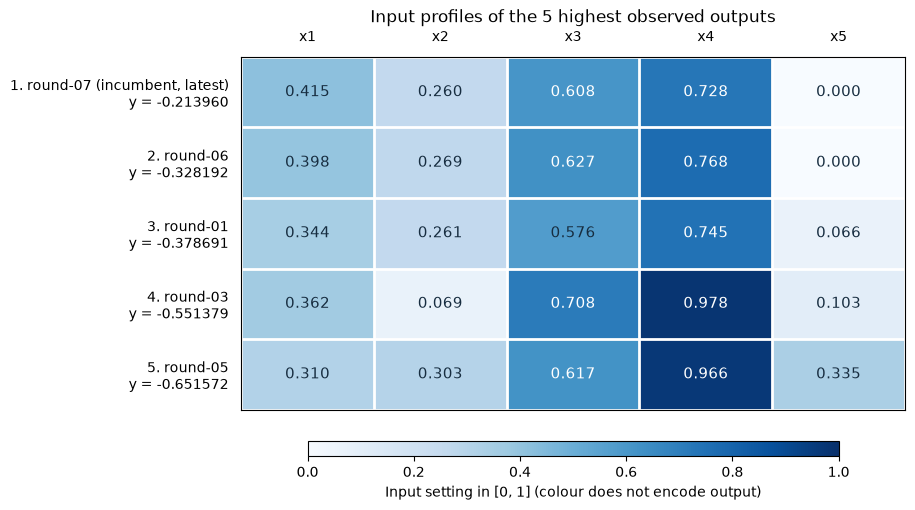

In [7]:
display(prepared["strongest"][["rank", "observation_id", "source_round", *INPUT_COLUMNS, OUTPUT_COLUMN]]
    .set_index("observation_id").style.format({column: "{:.6f}" for column in [*INPUT_COLUMNS, OUTPUT_COLUMN]}))
plot_input_profiles(
    prepared["strongest"], input_columns=INPUT_COLUMNS,
    latest_id=prepared["latest"]["observation_id"], incumbent_id=prepared["incumbent"]["observation_id"],
    save_to=FIGURES_DIR / "strongest-input-profiles.png",
)


### Latest input versus earlier evidence

Distances use every input coordinate. Similar input settings do not guarantee similar outputs or isolate the effect of one coordinate.

In [8]:
display(prepared["coordinate_changes"].style.format(precision=6))
display(pd.Series(prepared["neighbour_summary"]))


,Previous best,Latest query,Latest minus previous best
x1,0.398303,0.414821,0.016518
x2,0.269220,0.260324,-0.008896
x3,0.627336,0.607614,-0.019722
x4,0.768441,0.728412,-0.040029
x5,0.000000,0.000000,0.000000


previous_best_id              round-06
previous_best_output         -0.328192
distance_to_previous_best     0.048407
latest_minus_previous_best    0.114233
nearest_previous_id           round-06
nearest_previous_distance     0.048407
dtype: object

### Saved Week 7 forecasts at the submitted input

Read the preserved final selection record without refitting. GP latent SD and neural seed SD describe different quantities. Function 1 uses signed-log prediction units; its raw output is also retained. UCB is a selection score.

In [9]:
# Compare only forecasts recorded before the round 7 observation existed.
stage_dir = shared_dir.parent.parent
selection_path = stage_dir / "submissions/Week_07/proposals.json"
if hashlib.sha256(selection_path.read_bytes()).hexdigest() != "23cdcf011d52c2684166b6f1a0aff2bf18d9d542383053c452e0707a3cfb5676":
    raise ValueError("The historical Week 7 selection record has changed.")
selection = next(row for row in json.loads(selection_path.read_text(encoding="utf-8"))["candidates"]
                 if row["function"] == FUNCTION_NUMBER)
actual_point = prepared["latest"][INPUT_COLUMNS].to_numpy(dtype=float)
if not np.array_equal(actual_point, np.asarray(selection["point"], dtype=float)):
    raise ValueError("Saved forecast coordinates do not match the returned query.")
actual_output = float(prepared["latest"][OUTPUT_COLUMN])
actual_target = float(signed_log(actual_output, scale=1e-200)) if FUNCTION_NUMBER == 1 else actual_output
historical_forecast = dict(selection["predictions"])
historical_forecast.update(
    source=selection_path.relative_to(stage_dir).as_posix(), source_sha256="23cdcf011d52c2684166b6f1a0aff2bf18d9d542383053c452e0707a3cfb5676",
    data_scope=selection["data_scope"], selection_policy=selection["selection_policy"],
    prediction_units=selection["prediction_units"], actual_output=actual_output,
    actual_in_prediction_units=actual_target,
    actual_minus_gp_mean=actual_target - historical_forecast["gp_mean"],
    actual_minus_neural_mean=actual_target - historical_forecast["neural_mean"],
)
display(pd.Series(historical_forecast))


point                                   [0.414821, 0.260324, 0.607614, 0.728412, 0.0]
portal_input                             0.414821-0.260324-0.607614-0.728412-0.000000
gp_mean                                                                     -0.363908
gp_latent_sd                                                                 0.047498
gp_ucb_1_96                                                                 -0.270811
neural_mean                                                                 -0.341296
neural_seed_sd                                                               0.007583
neural_seed_predictions             [-0.34609109133050486, -0.3325534209510158, -0...
inside_selected_gp_training_hull                                                False
nearest_known_input_distance                                                 0.048407
source                                             submissions/Week_07/proposals.json
source_sha256                       23cdcf011d52c26841

### What the return adds

The returned score improved the previous best of -0.328192387858.

In [10]:
# Full-precision review record; tiny signed outputs are never rounded to zero.
observation_summary = {
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "observations": len(review["data"]),
    "latest_id": prepared["latest"]["observation_id"],
    "latest_output": float(prepared["latest"][OUTPUT_COLUMN]),
    "latest_rank": int(review["latest_submissions"].iloc[0]["output_rank"]),
    "rank_definition": "1 = highest output",
    "best_id": prepared["incumbent"]["observation_id"],
    "best_observed_output": float(prepared["incumbent"][OUTPUT_COLUMN]),
    "positive_outputs": int((review["outputs"] > 0).sum()),
    "negative_outputs": int((review["outputs"] < 0).sum()),
    "exact_zeros": int((review["outputs"] == 0).sum()),
    "progress": prepared["progress"].fillna("not_applicable").to_dict(orient="records"),
    "official_history_comparison": prepared["neighbour_summary"],
    "historical_forecast": historical_forecast,
    "remaining_queries": remaining_queries(WEEK_DIR),
}
(ANALYSIS_DIR / "observation-review.json").write_text(
    json.dumps(observation_summary, indent=2, allow_nan=False) + "\n", encoding="utf-8")
print(json.dumps(observation_summary, indent=2))


{
  "function": 6,
  "week": 8,
  "observations": 27,
  "latest_id": "round-07",
  "latest_output": -0.2139595403345748,
  "latest_rank": 1,
  "rank_definition": "1 = highest output",
  "best_id": "round-07",
  "best_observed_output": -0.2139595403345748,
  "positive_outputs": 0,
  "negative_outputs": 27,
  "exact_zeros": 0,
  "progress": [
    {
      "source_round": 0,
      "stage": "Initial batch",
      "returned_y": "not_applicable",
      "best_y": -0.7142649478202404,
      "change_vs_prior_best": "not_applicable"
    },
    {
      "source_round": 1,
      "stage": "Round 1",
      "returned_y": -0.3786912545484574,
      "best_y": -0.3786912545484574,
      "change_vs_prior_best": 0.335573693271783
    },
    {
      "source_round": 2,
      "stage": "Round 2",
      "returned_y": -1.1242807927769425,
      "best_y": -0.3786912545484574,
      "change_vs_prior_best": -0.7455895382284851
    },
    {
      "source_round": 3,
      "stage": "Round 3",
      "returned_y": -0.551

### Course lifecycle for this review

1. **Define the goal and scope** — review round 7 for the project owner and prepare evidence for the Week 8 decision; success means a reconciled return and an accurate descriptive review.
2. **Gather the data** — use the retained 12 November results email, original cumulative attachments and independent official CSV snapshot.
3. **Explore the data** — inspect measured ranks, progress and coverage or full input profiles.
4. **Clean and preprocess the data** — validate dimensions, bounds, finite values and round counts; preserve all rows and full float64 precision.
5. **Select and engineer features** — retain the existing ordered input coordinates; no engineered features are required.
6. **Define the machine-learning task** — continuous black-box maximisation remains the task; this notebook provides descriptive evidence.
7. **Partition the data** — not applicable: no new model is fitted or validated in this observation review.
8. **Select and train candidate methods** — not applicable: any Week 8 model comparison is separate work.
9. **Evaluate and interpret the results** — compare the measured return with earlier outputs, the prior incumbent and the saved forecast where one informed selection.
10. **Deploy and iterate** — no deployment applies; carry this evidence into the next query review. Six query opportunities remain, including Week 8; this notebook submits no query.
